# Q3 · Loss drivers: operating costs, refunds and Rewards

## tl;dr

Fuel and crew are the largest **measured adverse changes**; their growth and higher refunds explain about **89.5% of the $36.10 million decline** in the pre-gate contribution proxy. Flight growth drives most fuel and crew increases, while higher average cost per flight adds further pressure. Maintenance is another major contributor. Rewards participation and Points + Cash are observable, but **Rewards expense and its causal contribution to loss cannot be estimated from these files**.

All amounts are CAD. Exact results and qualifications follow; this is an analytical report for management, with reusable CSV tables and PNG/SVG figures.

## Context & methods

We compare **FY2024–25 (September 2024–August 2025)** with **FY2025–26 (September 2025–August 2026)** using `data/processed/transactions.csv` and `costs.csv`. The supplied case package identifies rising fuel and crew costs, disruption refunds and Rewards as potential explanations. The data dictionary defines transaction rows, negative refunds and four cost categories per flight.

The main outcome is **net recorded customer transactions minus recorded flight operating costs, before gate leases**. Revenue uses purchase/processing dates; costs use flight dates. This is a **purchase/flight contribution proxy**, not accrual operating profit or a matched-flight margin. The approximately $40 million loss in the narrative is contextual, not substituted for the computed result.

### Key assumptions

- Apply the user's **DD/MM/YYYY** interpretation only to the 7,902 residual ambiguous transaction dates (`assumed_day_first`). Keep all unambiguous dates and all 57 `resolved_duplicate` records. Exclude dates outside the two fiscal years; reconcile their counts and money below.
- Work in integer cents for additive totals; rates use unrounded inputs. Refunds retain negative signs. Membership/payment blanks become **Unknown**, so missing groups remain in totals.
- A flight is inferred from `(route_id, cost_date)`, then validated to contain exactly one of each of the four cost types. No transaction-to-flight join is attempted.
- The additive bridge explains accounting arithmetic. It does not establish why volume, prices, refunds or costs changed. The flight-cost split separates volume from **average cost per flight (including route/aircraft mix)**, not pure input-price inflation.
- Ticket counts are transactions/legs, not unique passengers. Refund-to-ticket ratios are period activity ratios, not matched cancellation rates. Rewards tiers are observed at booking; a booking identifier is not a persistent customer identifier.

No external research is used. Sources: `REAME.md`, the supplied case/data-dictionary PDFs, and processed CSVs only.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data/processed').exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from analysis_common import ROOT, FY_ORDER, COLORS, load_data, setup_style, save_figure, save_table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
from decimal import Decimal
from fractions import Fraction
import csv
setup_style()
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 12
money = lambda cents: f"${cents / 100:,.2f}"
tx_all = load_data('transactions')
cost_all = load_data('costs')
tx = tx_all.loc[tx_all.in_scope].copy()
cost = cost_all.loc[cost_all.in_scope].copy()
for col in ['membership_tier', 'payment_method']:
    tx[col] = tx[col].replace('', 'Unknown').fillna('Unknown')
assert tx_all.transaction_id.is_unique and cost_all.cost_id.is_unique
assert tx_all.transaction_date.notna().all() and cost_all.cost_date.notna().all()
assert tx.loc[tx.transaction_type.eq('Refund'), 'amount_cents'].lt(0).all()
assert tx.loc[tx.transaction_type.ne('Refund'), 'amount_cents'].gt(0).all()


## Data

### Reconcile dates before measuring change

The day-first assumption changes fiscal-year assignment, so reconcile the entire source before filtering. Counts and signed net CAD below include every transaction. Outside-period gross sales and refunds are shown separately rather than treating the net exclusion as a cost.

In [2]:
date_audit = (tx_all.groupby(['date_status', 'fiscal_year'], observed=True)
              .agg(transaction_rows=('transaction_id','size'), net_cents=('amount_cents','sum')).reset_index())
date_audit['net_cad'] = date_audit.net_cents / 100
save_table(date_audit, '03_date_reconciliation')
outside = tx_all.loc[~tx_all.in_scope]
outside_audit = outside.groupby('transaction_type').agg(rows=('transaction_id','size'), amount_cents=('amount_cents','sum')).reset_index()
outside_audit['amount_cad'] = outside_audit.amount_cents / 100
save_table(outside_audit, '03_excluded_transactions')
assert len(tx_all.loc[tx_all.date_status.eq('assumed_day_first')]) == 7902
assert len(outside) == 759 and outside.date_status.eq('assumed_day_first').all()
assert tx_all.date_status.eq('resolved_duplicate').sum() == 57
assert tx.date_status.eq('resolved_duplicate').sum() == 57
assert date_audit.transaction_rows.sum() == len(tx_all)
assert len(tx) + len(outside) == len(tx_all)
display(date_audit[['date_status','fiscal_year','transaction_rows','net_cad']])
display(outside_audit[['transaction_type','rows','amount_cad']])
display(Markdown(f"**Retained {len(tx):,} transaction rows; excluded {len(outside):,} rows totalling {money(outside.amount_cents.sum())} net.** All {len(cost):,} cost rows fall within the study period. The 7,902 assumed dates comprise 7,143 retained and 759 excluded rows."))


,date_status,fiscal_year,transaction_rows,net_cad
0,assumed_day_first,FY2024-25,3499,"2,354,595.37"
1,assumed_day_first,FY2025-26,3644,"2,484,457.44"
2,assumed_day_first,Outside study period,759,"499,209.97"
3,parsed,FY2024-25,266289,"178,050,805.59"
4,parsed,FY2025-26,283881,"187,203,226.63"
5,resolved_duplicate,FY2024-25,23,"14,042.12"
6,resolved_duplicate,FY2025-26,34,"22,687.73"


,transaction_type,rows,amount_cad
0,Change Fee,14,"1,200.00"
1,Extra Baggage,123,"5,848.08"
2,Food & Onboard,74,"1,338.07"
3,Refund,21,"-19,578.81"
4,Seat Upgrade,37,"2,084.53"
5,Ticket,490,"508,318.10"


**Retained 557,370 transaction rows; excluded 759 rows totalling $499,209.97 net.** All 115,204 cost rows fall within the study period. The 7,902 assumed dates comprise 7,143 retained and 759 excluded rows.

## Results

### 1. Reconcile every measured contributor to the decline

Calculate positive ticket sales, positive ancillary/fee sales and signed refunds separately. Subtract each operating-cost category. A cost increase produces a negative contribution to the outcome; a sales increase produces a positive contribution. The bridge must sum exactly, in cents, to the change between the two fiscal-year proxies.

In [3]:
revenue = tx.groupby(['fiscal_year','transaction_type']).amount_cents.sum().unstack(fill_value=0).reindex(FY_ORDER)
cost_by_type = cost.groupby(['fiscal_year','cost_type']).amount_cents.sum().unstack(fill_value=0).reindex(FY_ORDER)
ancillary_types = ['Extra Baggage','Seat Upgrade','Food & Onboard','Change Fee']
annual = pd.DataFrame(index=FY_ORDER)
annual['ticket_sales_cents'] = revenue.Ticket
annual['ancillary_sales_cents'] = revenue[ancillary_types].sum(axis=1)
annual['refunds_signed_cents'] = revenue.Refund
annual['net_revenue_cents'] = revenue.sum(axis=1)
annual['flight_cost_cents'] = cost_by_type.sum(axis=1)
annual['contribution_proxy_cents'] = annual.net_revenue_cents - annual.flight_cost_cents
annual.index.name='fiscal_year'
save_table(annual.reset_index(), '03_annual_exact_totals')
bridge_items = [('Ticket sales', annual.ticket_sales_cents.diff().iloc[1]),
                ('Ancillary / fees', annual.ancillary_sales_cents.diff().iloc[1]),
                ('Refunds', annual.refunds_signed_cents.diff().iloc[1])]
bridge_items += [(c, -cost_by_type[c].diff().iloc[1]) for c in ['Fuel','Crew','Maintenance','Food']]
bridge = pd.DataFrame(bridge_items, columns=['driver','change_in_proxy_cents'])
bridge['change_in_proxy_cents'] = bridge.change_in_proxy_cents.astype('int64')
bridge['change_in_proxy_cad'] = bridge.change_in_proxy_cents / 100
proxy_change = int(annual.contribution_proxy_cents.iloc[1] - annual.contribution_proxy_cents.iloc[0])
decline = -proxy_change
bridge['share_of_net_decline_pct'] = -bridge.change_in_proxy_cents / decline * 100
assert bridge.change_in_proxy_cents.sum() == proxy_change
save_table(bridge, '03_decline_bridge')
display(annual.rename(columns=lambda x:x.replace('_cents','_cad')) / 100)
display(bridge[['driver','change_in_proxy_cad','share_of_net_decline_pct']])
focus_adverse = -int(bridge.loc[bridge.driver.isin(['Fuel','Crew','Refunds']), 'change_in_proxy_cents'].sum())
display(Markdown(f"The proxy moves from **{money(annual.contribution_proxy_cents.iloc[0])}** to **{money(annual.contribution_proxy_cents.iloc[1])}**: a **{money(decline)} decline**. Fuel, crew and incremental refunds account for **{money(focus_adverse)}**, or **{focus_adverse/decline:.1%}** of that net decline. This denominator is net deterioration, so adverse shares need not sum to 100% when sales offset costs."))


,ticket_sales_cad,ancillary_sales_cad,refunds_signed_cad,net_revenue_cad,flight_cost_cad,contribution_proxy_cad
fiscal_year,,,,,,
FY2024-25,"183,426,906.51","3,670,848.26","-6,678,311.69","180,419,443.08","192,985,563.99","-12,566,120.91"
FY2025-26,"193,572,491.23","3,958,963.76","-7,821,083.19","189,710,371.80","238,376,476.25","-48,666,104.45"


,driver,change_in_proxy_cad,share_of_net_decline_pct
0,Ticket sales,"10,145,584.72",-28.10
1,Ancillary / fees,"288,115.50",-0.80
2,Refunds,"-1,142,771.50",3.17
3,Fuel,"-16,121,247.14",44.66
4,Crew,"-15,049,420.86",41.69
5,Maintenance,"-13,003,356.24",36.02
6,Food,"-1,216,888.02",3.37


The proxy moves from **$-12,566,120.91** to **$-48,666,104.45**: a **$36,099,983.54 decline**. Fuel, crew and incremental refunds account for **$32,313,439.50**, or **89.5%** of that net decline. This denominator is net deterioration, so adverse shares need not sum to 100% when sales offset costs.

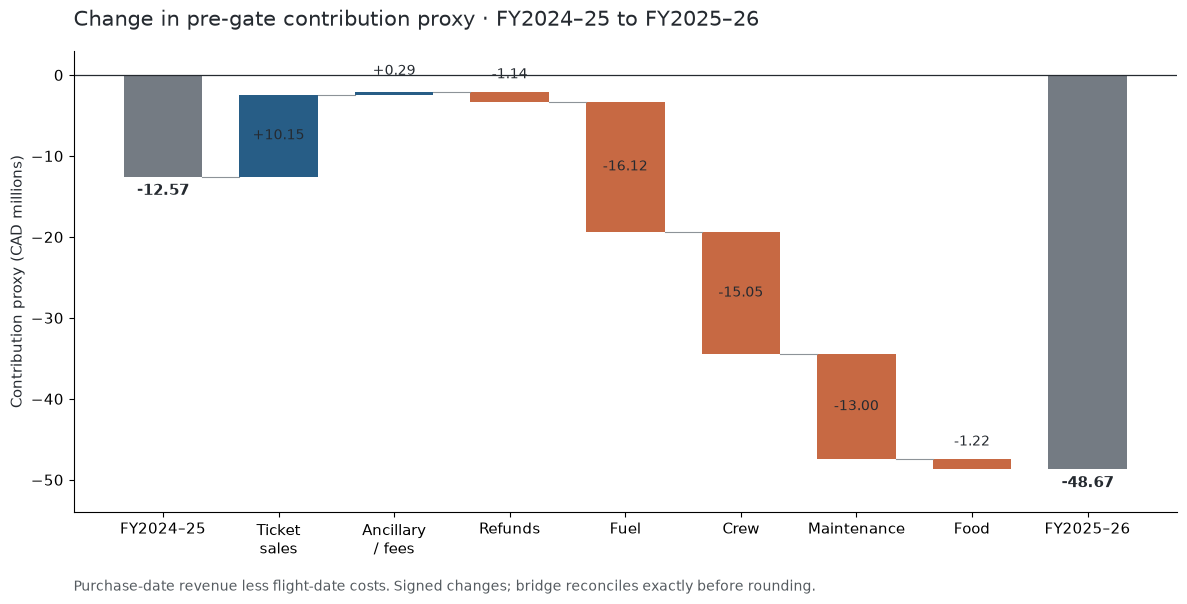

In [4]:
fig, ax = plt.subplots(figsize=(12,6.2))
start = annual.contribution_proxy_cents.iloc[0] / 1e8
end = annual.contribution_proxy_cents.iloc[1] / 1e8
labels = ['FY2024–25', 'Ticket\nsales','Ancillary\n/ fees','Refunds','Fuel','Crew','Maintenance','Food','FY2025–26']
ax.bar(0,start,color=COLORS['grey'],width=.68)
running = start
for i, row in enumerate(bridge.itertuples(),1):
    delta = row.change_in_proxy_cents / 1e8
    bottom = min(running, running + delta)
    ax.bar(i,abs(delta),bottom=bottom,color=COLORS['blue'] if delta > 0 else COLORS['orange'],width=.68)
    ax.plot([i-.66,i-.34],[running,running],color='#8D9398',lw=.8)
    center = bottom + abs(delta)/2
    ax.annotate(f'{delta:+.2f}',(i,center),xytext=(0,16 if abs(delta)<2 else 0),textcoords='offset points',ha='center',va='center',fontsize=10)
    running += delta
ax.bar(8,end,color=COLORS['grey'],width=.68)
ax.text(0,start-.8,f'{start:.2f}',ha='center',va='top',weight='bold')
ax.text(8,end-.8,f'{end:.2f}',ha='center',va='top',weight='bold')
ax.axhline(0,color='#252A30',lw=.9)
ax.set_xticks(range(9),labels); ax.set_ylim(-54,3)
ax.set_ylabel('Contribution proxy (CAD millions)')
ax.set_title('Change in pre-gate contribution proxy · FY2024–25 to FY2025–26',loc='left',pad=18)
ax.text(0,-.17,'Purchase-date revenue less flight-date costs. Signed changes; bridge reconciles exactly before rounding.',transform=ax.transAxes,fontsize=10,color='#555B60')
fig.tight_layout(); save_figure(fig,'03_decline_bridge'); plt.show()


**Interpretation.** Fuel and crew are the two largest individual adverse movements. Maintenance is also substantial; attributing the deterioration to fuel, crew and refunds alone would omit a material operating-cost increase. Sales growth offsets part of the adverse movements. Rewards cannot be added as another expense here: the source ledger supplies no distinct Rewards expense line, and Points + Cash receipts already sit within recorded transactions.

### 2. Separate more flights from higher average cost per flight

Validate the inferred flight grain before using a per-flight denominator. For each cost category, use an exact sequential decomposition:

**cost growth = (FY26 flights − FY25 flights) × FY25 average cost + FY26 flights × (FY26 average cost − FY25 average cost)**.

The first term holds FY25 average cost constant. The second absorbs within-route cost changes **and changes in route, stage length or aircraft mix**. Fraction arithmetic verifies exact reconciliation; displayed component dollars can contain fractions of a cent because an average is involved.

In [5]:
flight_keys = ['route_id','cost_date']
flight_check = cost.groupby(flight_keys).agg(rows=('cost_id','size'), cost_categories=('cost_type','nunique'), fiscal_year=('fiscal_year','first'))
assert flight_check.rows.eq(4).all() and flight_check.cost_categories.eq(4).all()
assert not cost.duplicated(flight_keys+['cost_type']).any()
assert set(cost.cost_type.unique()) == {'Fuel','Crew','Maintenance','Food'}
flights = flight_check.groupby('fiscal_year').size().reindex(FY_ORDER)
rows=[]
for component in ['Fuel','Crew','Maintenance','Food']:
    n0,n1=map(int,flights); c0,c1=map(int,cost_by_type[component])
    u0,u1=Fraction(c0,n0),Fraction(c1,n1)
    volume=(n1-n0)*u0; unit=n1*(u1-u0)
    assert volume+unit == c1-c0
    rows.append({'cost_type':component,'fy25_flights':n0,'fy26_flights':n1,
                 'fy25_cost_cents':c0,'fy26_cost_cents':c1,'growth_cents':c1-c0,
                 'fy25_cost_per_flight_cad':float(u0/100),'fy26_cost_per_flight_cad':float(u1/100),
                 'average_cost_growth_pct':float((u1/u0-1)*100),
                 'volume_effect_cad':float(volume/100),'average_cost_mix_effect_cad':float(unit/100)})
cost_split=pd.DataFrame(rows)
save_table(cost_split,'03_cost_volume_and_average')
display(cost_split[['cost_type','fy25_cost_per_flight_cad','fy26_cost_per_flight_cad','average_cost_growth_pct','volume_effect_cad','average_cost_mix_effect_cad']])
display(Markdown(f"**Flights increase from {flights.iloc[0]:,} to {flights.iloc[1]:,} ({flights.iloc[1]/flights.iloc[0]-1:.2%}).** Each of the {len(flight_check):,} flight keys has four unique cost categories and no repeated category."))


,cost_type,fy25_cost_per_flight_cad,fy26_cost_per_flight_cad,average_cost_growth_pct,volume_effect_cad,average_cost_mix_effect_cad
0,Fuel,"5,130.13","5,288.47",3.09,"13,630,760.23","2,490,486.91"
1,Crew,"4,568.37","4,753.46",4.05,"12,138,158.45","2,911,262.41"
2,Maintenance,"4,466.35","4,538.59",1.62,"11,867,091.24","1,136,265.00"
3,Food,598.43,574.70,-3.96,"1,590,018.50","-373,130.48"


**Flights increase from 13,072 to 15,729 (20.33%).** Each of the 28,801 flight keys has four unique cost categories and no repeated category.

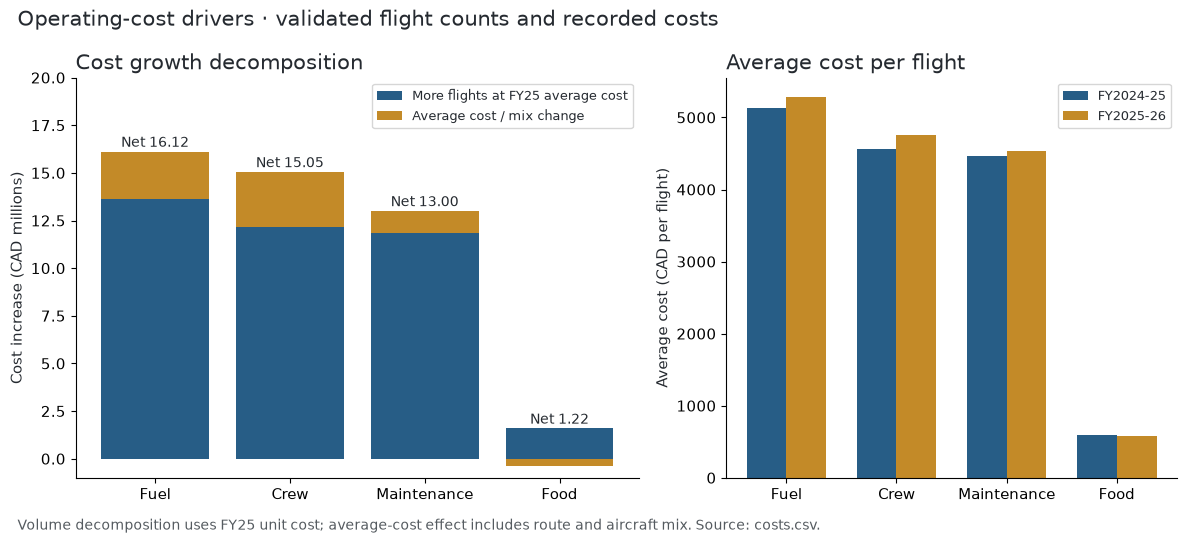

In [6]:
fig, axes=plt.subplots(1,2,figsize=(12,5.2),gridspec_kw={'width_ratios':[1.25,1]})
x=np.arange(len(cost_split)); vol=cost_split.volume_effect_cad/1e6; unit=cost_split.average_cost_mix_effect_cad/1e6
axes[0].bar(x,vol,color=COLORS['blue'],label='More flights at FY25 average cost')
axes[0].bar(x,unit,bottom=np.where(unit>=0,vol,0),color=COLORS['gold'],label='Average cost / mix change')
for i,row in cost_split.iterrows():
    axes[0].text(i,max(row.growth_cents/1e8,row.volume_effect_cad/1e6)+.25,f'Net {row.growth_cents/1e8:.2f}',ha='center',fontsize=10)
axes[0].set_xticks(x,cost_split.cost_type);axes[0].set_ylabel('Cost increase (CAD millions)');axes[0].set_title('Cost growth decomposition',loc='left');axes[0].legend(fontsize=9,loc='upper right');axes[0].set_ylim(-1,20)
for idx,(fy,col) in enumerate(zip(FY_ORDER,['fy25_cost_per_flight_cad','fy26_cost_per_flight_cad'])):
    axes[1].bar(x+(idx-.5)*.36,cost_split[col],width=.36,label=fy,color=[COLORS['blue'],COLORS['gold']][idx])
axes[1].set_xticks(x,cost_split.cost_type); axes[1].set_ylabel('Average cost (CAD per flight)');axes[1].set_title('Average cost per flight',loc='left');axes[1].legend(fontsize=9)
fig.suptitle('Operating-cost drivers · validated flight counts and recorded costs',x=.02,ha='left',fontsize=15)
fig.text(.02,-.02,'Volume decomposition uses FY25 unit cost; average-cost effect includes route and aircraft mix. Source: costs.csv.',fontsize=10,color='#555B60')
fig.tight_layout(); save_figure(fig,'03_cost_volume_average');plt.show()


In [7]:
fc=cost_split.loc[cost_split.cost_type.isin(['Fuel','Crew'])]
display(Markdown(f"For fuel and crew combined, **${fc.volume_effect_cad.sum():,.2f}** of cost growth is associated arithmetically with flight volume and **${fc.average_cost_mix_effect_cad.sum():,.2f}** with average cost/mix. The volume component is **{fc.volume_effect_cad.sum()/(fc.growth_cents.sum()/100):.1%}** of their total increase. Average fuel cost per flight rises **{cost_split.set_index('cost_type').loc['Fuel','average_cost_growth_pct']:.2f}%** and crew **{cost_split.set_index('cost_type').loc['Crew','average_cost_growth_pct']:.2f}%**, broadly consistent with the case's approximate 3% and 4%. Schedule/network economics therefore warrant scrutiny alongside unit-cost management; this calculation does not imply that cutting any particular flight saves the average cost."))


For fuel and crew combined, **$25,768,918.68** of cost growth is associated arithmetically with flight volume and **$5,401,749.32** with average cost/mix. The volume component is **82.7%** of their total increase. Average fuel cost per flight rises **3.09%** and crew **4.05%**, broadly consistent with the case's approximate 3% and 4%. Schedule/network economics therefore warrant scrutiny alongside unit-cost management; this calculation does not imply that cutting any particular flight saves the average cost.

### 3. Quantify refunds without calling them cancellations

Refund rows are negative cash transactions. Sum their absolute value, count the records, calculate the average absolute refund, and divide refund amounts by positive customer sales. These processing-period measures capture refund pressure; the files do not reveal disruption reason, flight cancellation status, compensation expense or a matched flown cohort.

In [8]:
refund_rows=tx.loc[tx.transaction_type.eq('Refund')]
refunds=refund_rows.groupby('fiscal_year').agg(refund_records=('transaction_id','size'), refunds_signed_cents=('amount_cents','sum')).reindex(FY_ORDER)
refunds['refund_outflow_cad']=-refunds.refunds_signed_cents/100
refunds['average_refund_cad']=refunds.refund_outflow_cad/refunds.refund_records
refunds['ticket_records']=tx.loc[tx.transaction_type.eq('Ticket')].groupby('fiscal_year').size().reindex(FY_ORDER)
refunds['refund_records_per_100_tickets']=refunds.refund_records/refunds.ticket_records*100
refunds['positive_sales_cad']=(annual.ticket_sales_cents+annual.ancillary_sales_cents)/100
refunds['refund_outflow_share_positive_sales_pct']=refunds.refund_outflow_cad/refunds.positive_sales_cad*100
save_table(refunds.reset_index(),'03_refund_metrics')
monthly_positive=tx.loc[tx.transaction_type.ne('Refund')].groupby('month').amount_cents.sum()
monthly_refund=-refund_rows.groupby('month').amount_cents.sum()
monthly=pd.DataFrame({'positive_sales_cents':monthly_positive,'refund_outflow_cents':monthly_refund}).fillna(0)
monthly['refund_outflow_share_positive_sales_pct']=monthly.refund_outflow_cents/monthly.positive_sales_cents*100
save_table(monthly.reset_index(),'03_monthly_refunds')
display(refunds.drop(columns=['refunds_signed_cents']))
refund_growth=int(-(annual.refunds_signed_cents.iloc[1]-annual.refunds_signed_cents.iloc[0]))
display(Markdown(f"Refund outflows rise by **{money(refund_growth)}** (**{refunds.refund_outflow_cad.iloc[1]/refunds.refund_outflow_cad.iloc[0]-1:.1%}**), accounting for **{refund_growth/decline:.1%}** of the net deterioration. Refund counts rise **{refunds.refund_records.iloc[1]/refunds.refund_records.iloc[0]-1:.1%}**; average refund amounts rise **{refunds.average_refund_cad.iloc[1]/refunds.average_refund_cad.iloc[0]-1:.1%}**. This is a smaller measured driver than fuel, crew or maintenance, while remaining a customer-service priority."))


,refund_records,refund_outflow_cad,average_refund_cad,ticket_records,refund_records_per_100_tickets,positive_sales_cad,refund_outflow_share_positive_sales_pct
fiscal_year,,,,,,,
FY2024-25,6234,"6,678,311.69","1,071.27",178217,3.50,"187,097,754.77",3.57
FY2025-26,7265,"7,821,083.19","1,076.54",187444,3.88,"197,531,454.99",3.96


Refund outflows rise by **$1,142,771.50** (**17.1%**), accounting for **3.2%** of the net deterioration. Refund counts rise **16.5%**; average refund amounts rise **0.5%**. This is a smaller measured driver than fuel, crew or maintenance, while remaining a customer-service priority.

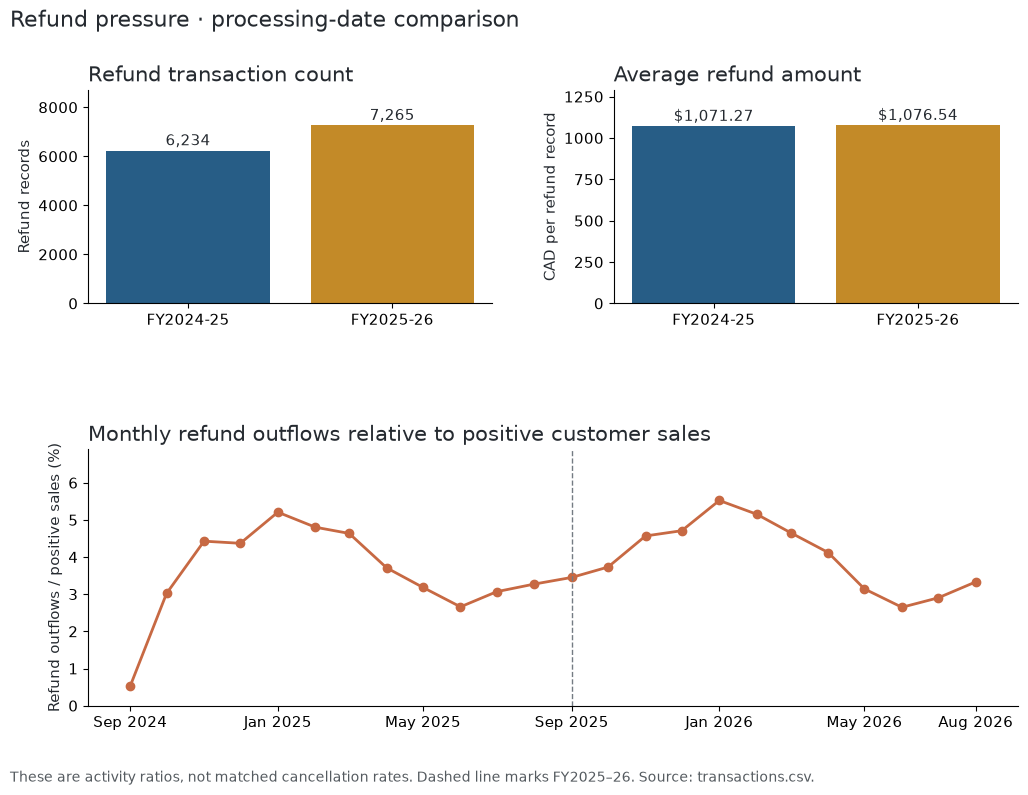

In [9]:
fig=plt.figure(figsize=(12,8));gs=fig.add_gridspec(2,2,height_ratios=[1,1.2],hspace=.62,wspace=.3)
for ax,col,title,ylabel in [(fig.add_subplot(gs[0,0]),'refund_records','Refund transaction count','Refund records'),(fig.add_subplot(gs[0,1]),'average_refund_cad','Average refund amount','CAD per refund record')]:
    vals=refunds[col].to_numpy(); ax.bar(FY_ORDER,vals,color=[COLORS['blue'],COLORS['gold']]);ax.set_ylim(0,max(vals)*1.2);ax.set_title(title,loc='left');ax.set_ylabel(ylabel)
    for i,v in enumerate(vals):ax.text(i,v+max(vals)*.03,f'{v:,.0f}' if col=='refund_records' else f'${v:,.2f}',ha='center')
ax=fig.add_subplot(gs[1,:]);dates=pd.to_datetime(monthly.index)
ax.plot(dates,monthly.refund_outflow_share_positive_sales_pct,color=COLORS['orange'],marker='o',lw=2)
ax.axvline(pd.Timestamp('2025-09-01'),color='#747B83',ls='--',lw=1)
positions=[0,4,8,12,16,20,23];ax.set_xticks(dates[positions],dates[positions].strftime('%b %Y'));ax.set_ylim(0,max(monthly.refund_outflow_share_positive_sales_pct)*1.25)
ax.set_title('Monthly refund outflows relative to positive customer sales',loc='left');ax.set_ylabel('Refund outflows / positive sales (%)')
fig.suptitle('Refund pressure · processing-date comparison',x=.06,ha='left',fontsize=16)
fig.text(.06,.015,'These are activity ratios, not matched cancellation rates. Dashed line marks FY2025–26. Source: transactions.csv.',fontsize=10,color='#555B60')
save_figure(fig,'03_refund_pressure');plt.show()


### 4. Measure Rewards exposure and preserve the identification limit

The case describes a free membership program with tier perks and Points + Cash payments. We can measure ticket receipts, transaction counts and observed means by membership/payment category. We cannot infer point redemption cost, an unrecorded discount, foregone cash revenue, point liability, benefit expense or incremental customer retention. There is no no-program counterfactual or consistent customer panel.

Calculate both membership and payment tables, retaining Unknown categories. These are alternative partitions of the same ticket sales: **do not add their amounts together**. A Points + Cash ticket's recorded amount is its observed receipt, not a full cash-equivalent fare.

In [10]:
tickets=tx.loc[tx.transaction_type.eq('Ticket')].copy()
member_order=['Non-Member','Blue','Silver','Gold','Platinum','Unknown']
payment_order=['Credit Card','Debit','Points + Cash','Travel Voucher','Unknown']
def ticket_group(field, order):
    table=(tickets.groupby(['fiscal_year',field]).agg(ticket_records=('transaction_id','size'),ticket_receipts_cents=('amount_cents','sum')).reset_index())
    table['ticket_receipts_cad']=table.ticket_receipts_cents/100
    table['mean_recorded_ticket_cad']=table.ticket_receipts_cad/table.ticket_records
    table['ticket_record_share_pct']=table.ticket_records/table.groupby('fiscal_year').ticket_records.transform('sum')*100
    table['receipt_share_pct']=table.ticket_receipts_cents/table.groupby('fiscal_year').ticket_receipts_cents.transform('sum')*100
    table[field]=pd.Categorical(table[field],categories=order,ordered=True)
    return table.sort_values([field,'fiscal_year']).reset_index(drop=True)
membership=ticket_group('membership_tier',member_order);payments=ticket_group('payment_method',payment_order)
for table,label in [(membership,'membership'),(payments,'payment')]:
    assert table.groupby('fiscal_year',observed=True).ticket_receipts_cents.sum().reindex(FY_ORDER).equals(annual.ticket_sales_cents)
    save_table(table,'03_rewards_'+label)
    display(table.drop(columns='ticket_receipts_cents'))
# All transaction types show net contributions by tier, without attributing costs.
tier_net=(tx.groupby(['fiscal_year','membership_tier']).agg(transaction_records=('transaction_id','size'),net_receipts_cents=('amount_cents','sum')).reset_index())
tier_net['net_receipts_cad']=tier_net.net_receipts_cents/100
save_table(tier_net,'03_membership_net_receipts')


,fiscal_year,membership_tier,ticket_records,ticket_receipts_cad,mean_recorded_ticket_cad,ticket_record_share_pct,receipt_share_pct
0,FY2024-25,Non-Member,88282,"90,925,410.09","1,029.94",49.54,49.57
1,FY2025-26,Non-Member,92533,"95,444,402.59","1,031.46",49.37,49.31
2,FY2024-25,Blue,43621,"44,797,535.39","1,026.97",24.48,24.42
3,FY2025-26,Blue,45981,"47,490,299.30","1,032.82",24.53,24.53
4,FY2024-25,Silver,24183,"24,900,352.44","1,029.66",13.57,13.58
5,FY2025-26,Silver,25735,"26,607,124.94","1,033.89",13.73,13.75
6,FY2024-25,Gold,14281,"14,744,771.26","1,032.47",8.01,8.04
7,FY2025-26,Gold,14858,"15,374,445.14","1,034.76",7.93,7.94
8,FY2024-25,Platinum,5216,"5,352,637.57","1,026.20",2.93,2.92
9,FY2025-26,Platinum,5549,"5,764,758.93","1,038.88",2.96,2.98


,fiscal_year,payment_method,ticket_records,ticket_receipts_cad,mean_recorded_ticket_cad,ticket_record_share_pct,receipt_share_pct
0,FY2024-25,Credit Card,115247,"118,482,661.92","1,028.08",64.67,64.59
1,FY2025-26,Credit Card,120792,"124,740,975.93","1,032.69",64.44,64.44
2,FY2024-25,Debit,34942,"36,178,126.51","1,035.38",19.61,19.72
3,FY2025-26,Debit,37040,"38,172,767.18","1,030.58",19.76,19.72
4,FY2024-25,Points + Cash,18010,"18,444,417.90","1,024.12",10.11,10.06
5,FY2025-26,Points + Cash,19050,"19,739,857.11","1,036.21",10.16,10.20
6,FY2024-25,Travel Voucher,8565,"8,791,510.45","1,026.45",4.81,4.79
7,FY2025-26,Travel Voucher,9052,"9,353,217.96","1,033.28",4.83,4.83
8,FY2024-25,Unknown,1453,"1,530,189.73","1,053.12",0.82,0.83
9,FY2025-26,Unknown,1510,"1,565,673.05","1,036.87",0.81,0.81


PosixPath('/home/vvict/projects/firstByte-2026/outputs/tables/03_membership_net_receipts.csv')

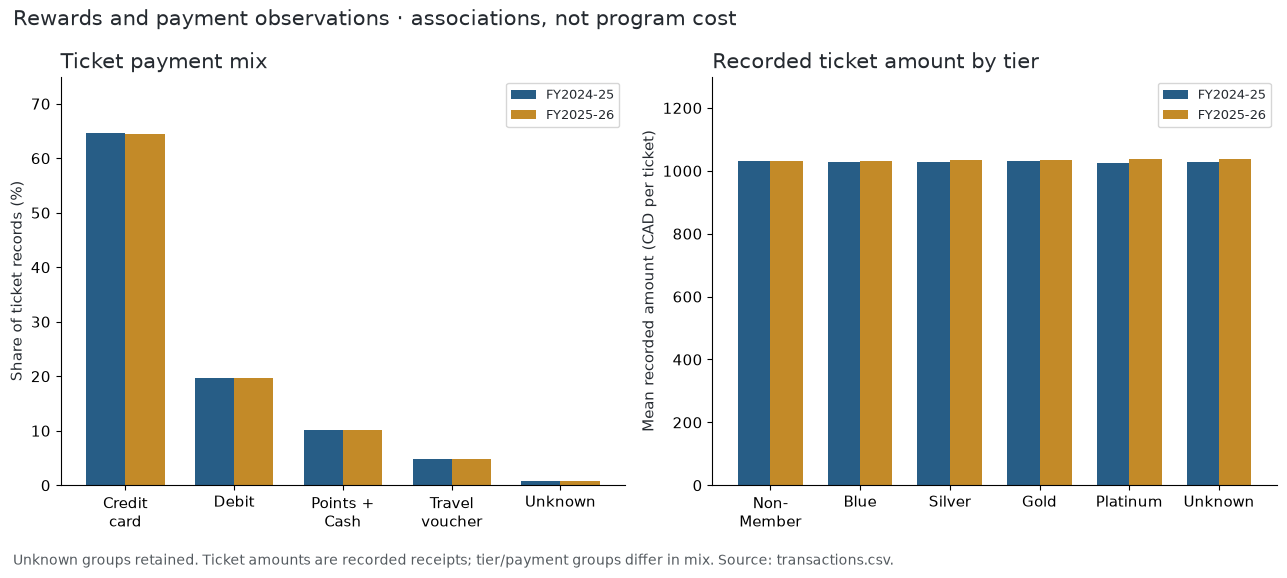

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
for ax,table,group,order,value,title,ylabel in [
    (axes[0],payments,'payment_method',payment_order,'ticket_record_share_pct','Ticket payment mix','Share of ticket records (%)'),
    (axes[1],membership,'membership_tier',member_order,'mean_recorded_ticket_cad','Recorded ticket amount by tier','Mean recorded amount (CAD per ticket)')]:
    pivot=table.pivot(index=group,columns='fiscal_year',values=value).reindex(order)
    x=np.arange(len(order))
    for i,fy in enumerate(FY_ORDER):
        ax.bar(x+(i-.5)*.36,pivot[fy],width=.36,label=fy,color=[COLORS['blue'],COLORS['gold']][i])
    labels=[s.replace('Credit Card','Credit\ncard').replace('Points + Cash','Points +\nCash').replace('Travel Voucher','Travel\nvoucher').replace('Non-Member','Non-\nMember') for s in order]
    ax.set_xticks(x,labels);ax.set_title(title,loc='left');ax.set_ylabel(ylabel);ax.set_ylim(0,1300 if value=='mean_recorded_ticket_cad' else 75);ax.legend(fontsize=9)
fig.suptitle('Rewards and payment observations · associations, not program cost',x=.015,ha='left',fontsize=15)
fig.text(.015,-.03,'Unknown groups retained. Ticket amounts are recorded receipts; tier/payment groups differ in mix. Source: transactions.csv.',fontsize=10,color='#555B60')
fig.tight_layout();save_figure(fig,'03_rewards_observations');plt.show()


In [12]:
p26=payments.loc[(payments.fiscal_year==FY_ORDER[1]) & (payments.payment_method=='Points + Cash')].iloc[0]
p25=payments.loc[(payments.fiscal_year==FY_ORDER[0]) & (payments.payment_method=='Points + Cash')].iloc[0]
u26=membership.loc[(membership.fiscal_year==FY_ORDER[1]) & (membership.membership_tier=='Unknown')].iloc[0]
up26=payments.loc[(payments.fiscal_year==FY_ORDER[1]) & (payments.payment_method=='Unknown')].iloc[0]
member_tickets=membership.loc[~membership.membership_tier.isin(['Non-Member','Unknown'])].groupby('fiscal_year',observed=True).ticket_receipts_cents.sum()
display(Markdown(f"**Points + Cash exposure:** FY26 has **{int(p26.ticket_records):,} ticket records**, **${p26.ticket_receipts_cad:,.2f} recorded receipts**, **{p26.ticket_record_share_pct:.2f}% of ticket records**, and a **${p26.mean_recorded_ticket_cad:,.2f} mean recorded ticket amount**. Receipts increase by **${p26.ticket_receipts_cad-p25.ticket_receipts_cad:,.2f}**. Known member-tier ticket receipts increase from **{money(member_tickets.iloc[0])}** to **{money(member_tickets.iloc[1])}**. These observations do not measure incremental program value or cost.\n\n**Unknown coverage is material:** FY26 unknown membership includes **{int(u26.ticket_records):,} tickets / ${u26.ticket_receipts_cad:,.2f}**; unknown payment includes **{int(up26.ticket_records):,} tickets / ${up26.ticket_receipts_cad:,.2f}**. They remain visible in all relevant totals.\n\nThere is **no measured Rewards expense** in the provided cost categories. This is an **unquantified contribution**, not a zero-cost finding. Similar average ticket receipts by tier do not identify a discount or program effect; route, booking timing, journey and customer mix can differ."))


**Points + Cash exposure:** FY26 has **19,050 ticket records**, **$19,739,857.11 recorded receipts**, **10.16% of ticket records**, and a **$1,036.21 mean recorded ticket amount**. Receipts increase by **$1,295,439.21**. Known member-tier ticket receipts increase from **$89,795,296.66** to **$95,236,628.31**. These observations do not measure incremental program value or cost.

**Unknown coverage is material:** FY26 unknown membership includes **2,788 tickets / $2,891,460.33**; unknown payment includes **1,510 tickets / $1,565,673.05**. They remain visible in all relevant totals.

There is **no measured Rewards expense** in the provided cost categories. This is an **unquantified contribution**, not a zero-cost finding. Similar average ticket receipts by tier do not identify a discount or program effect; route, booking timing, journey and customer mix can differ.

### 5. Independently verify the accounting result

Re-read the processed CSVs with Python's CSV reader and Decimal money conversion, independently of the shared loader and pandas groupings. Assign fiscal years directly from the normalized date strings, then cross-check all fiscal-year revenue and cost totals in cents. Also reconcile the refund and membership/payment partitions to their parent totals.

In [13]:
independent={name:{fy:0 for fy in FY_ORDER} for name in ['transactions','costs']}
for name,datefield in [('transactions','transaction_date'),('costs','cost_date')]:
    with (ROOT/'data/processed'/f'{name}.csv').open(newline='') as handle:
        for row in csv.DictReader(handle):
            date=row[datefield][:10]
            fy=FY_ORDER[0] if '2024-09-01'<=date<'2025-09-01' else FY_ORDER[1] if '2025-09-01'<=date<'2026-09-01' else None
            if fy:
                exact=Decimal(row['amount'])*100
                assert exact == exact.to_integral_value()
                independent[name][fy]+=int(exact)
for fy in FY_ORDER:
    assert independent['transactions'][fy] == int(annual.loc[fy,'net_revenue_cents'])
    assert independent['costs'][fy] == int(annual.loc[fy,'flight_cost_cents'])
    assert independent['transactions'][fy]-independent['costs'][fy] == int(annual.loc[fy,'contribution_proxy_cents'])
assert int(refunds.refunds_signed_cents.sum()) == int(tx.loc[tx.transaction_type.eq('Refund'),'amount_cents'].sum())
assert tier_net.net_receipts_cents.sum() == tx.amount_cents.sum()
assert len(cost)==len(flight_check)*4
validation=pd.DataFrame([
    ['Independent Decimal fiscal-year totals', 'PASS'],
    ['Exact-cent additive bridge', 'PASS'],
    ['Four unique cost records per inferred flight', 'PASS'],
    ['Date scope / 7,902 assumptions / 57 retained resolved records', 'PASS'],
    ['Refund and membership/payment partitions', 'PASS'],
],columns=['check','result'])
save_table(validation,'03_validation');display(validation)


,check,result
0,Independent Decimal fiscal-year totals,PASS
1,Exact-cent additive bridge,PASS
2,Four unique cost records per inferred flight,PASS
3,"Date scope / 7,902 assumptions / 57 retained r...",PASS
4,Refund and membership/payment partitions,PASS


## Takeaways

1. **Prioritize flight economics and fuel/crew management.** They dominate measured adverse change; flight volume explains most of their combined increase. Review marginal route/frequency contribution alongside safe operating requirements. Average-cost components cannot be interpreted as avoidable savings.
2. **Include maintenance in the diagnosis.** Its increase is much larger than incremental refunds. Validate whether growth, fleet/route mix or maintenance intensity explains it before targeting reductions.
3. **Reduce disruption-related customer harm.** Refund leakage is measurable but smaller. The data do not support removing refund protections or attributing each refund to weather or service failure.
4. **Audit Rewards economics before changing the program.** Obtain issued/redeemed points, liability and unit value, fare equivalent/discount detail, benefit/vendor costs and customer retention data. Use a credible comparison design to estimate incremental contribution. Do not label recorded Points + Cash receipts as Rewards cost.

Figures and exact-value tables are written to `outputs/figures/03_*` and `outputs/tables/03_*`. The stand-alone synthesis handoff is `outputs/reports/03_loss_drivers.txt`. This notebook keeps the purchase/flight timing limitation, date exclusions and causal limits alongside the findings.

In [14]:
report_dir=ROOT/'outputs/reports';report_dir.mkdir(parents=True,exist_ok=True)
report=f"""Q3 LOSS DRIVERS — CAD; FY2024-25 versus FY2025-26

Outcome: purchase-date net revenue less flight-date operating costs before gate leases; a contribution proxy, not accrual profit.
FY25 net revenue {money(annual.net_revenue_cents.iloc[0])}; operating costs {money(annual.flight_cost_cents.iloc[0])}; proxy {money(annual.contribution_proxy_cents.iloc[0])}.
FY26 net revenue {money(annual.net_revenue_cents.iloc[1])}; operating costs {money(annual.flight_cost_cents.iloc[1])}; proxy {money(annual.contribution_proxy_cents.iloc[1])}.
Decline: {money(decline)}.

Exact additive changes in contribution proxy:
{bridge[['driver','change_in_proxy_cad','share_of_net_decline_pct']].to_string(index=False)}
Fuel, crew and higher refunds together: {money(focus_adverse)}, {focus_adverse/decline:.2%} of net decline. Maintenance is another material adverse driver; positive sales offset some cost growth. Shares refer to net deterioration and are arithmetic, not causal estimates.

Validated flights: {flights.iloc[0]:,} to {flights.iloc[1]:,}, {flights.iloc[1]/flights.iloc[0]-1:.2%} growth. Each route/date key has exactly four unique cost categories.
Fuel+crew growth decomposes into volume ${fc.volume_effect_cad.sum():,.2f} and average-cost/mix ${fc.average_cost_mix_effect_cad.sum():,.2f}; volume is {fc.volume_effect_cad.sum()/(fc.growth_cents.sum()/100):.2%} of combined growth. This uses FY25 average cost for the volume component; average-cost effect includes route/aircraft/stage-length mix, not pure input prices. It is not an estimate of avoidable savings.

Refund metrics:
{refunds.drop(columns=['refunds_signed_cents']).to_string()}
Refund outflow increase {money(refund_growth)} explains {refund_growth/decline:.2%} of deterioration. Refund activity ratios are not matched cancellation rates; disruption causes are unobserved.

Rewards: no program expense, redemption liability, points unit value, fare-equivalent discount or causal comparison is provided. Program contribution is unquantified, not zero. FY26 Points + Cash tickets: {int(p26.ticket_records):,}; recorded receipts ${p26.ticket_receipts_cad:,.2f}; ticket-record share {p26.ticket_record_share_pct:.2f}%; mean recorded amount ${p26.mean_recorded_ticket_cad:,.2f}. Receipts grew ${p26.ticket_receipts_cad-p25.ticket_receipts_cad:,.2f}. Do not treat receipts or member-vs-nonmember mean differences as program cost or causal loss. Membership/payment are overlapping alternative partitions; never sum them. Unknown membership FY26 ticket receipts ${u26.ticket_receipts_cad:,.2f} ({int(u26.ticket_records):,} tickets); unknown payment ${up26.ticket_receipts_cad:,.2f} ({int(up26.ticket_records):,} tickets).

Scope: user's DD/MM/YYYY assumption applied to 7,902 residual ambiguous dates only; 7,143 in scope, 759 outside. Excluded rows net {money(outside.amount_cents.sum())}; gross positives {money(outside.loc[outside.transaction_type.ne('Refund'),'amount_cents'].sum())}; refunds signed {money(outside.loc[outside.transaction_type.eq('Refund'),'amount_cents'].sum())}. Keep all 57 resolved_duplicate rows and all unambiguous dates. All costs in scope. No gate leases or external research.

Sources: REAME.md; FirstByte 2026 Case Package.pdf; FirstByte 2026 Data Dictionary.pdf; data/processed/transactions.csv and costs.csv.
Validation: independent raw processed CSV/Decimal year totals match; exact-cent bridge; flight grain; date counts; group partitions. Notebook executed top to bottom.

Notebook: notebooks/03_loss_drivers.ipynb
Figures (PNG + SVG): outputs/figures/03_decline_bridge, 03_cost_volume_average, 03_refund_pressure, 03_rewards_observations.
Tables (CSV): outputs/tables/03_annual_exact_totals, 03_decline_bridge, 03_cost_volume_and_average, 03_refund_metrics, 03_monthly_refunds, 03_rewards_membership, 03_rewards_payment, 03_membership_net_receipts, 03_date_reconciliation, 03_excluded_transactions, 03_validation.
"""
(report_dir/'03_loss_drivers.txt').write_text(report)
print('Saved Q3 handoff report and figure/table artifacts.')


Saved Q3 handoff report and figure/table artifacts.


## Answer to Question 3

**Fuel and crew matter most among the measured drivers.** Between FY2024–25 and FY2025–26, the pre-gate contribution proxy deteriorates by **$36,099,983.54**, from **−$12,566,120.91** to **−$48,666,104.45**. Higher fuel cost contributes **$16,121,247.14 (44.66% of the decline)**, higher crew cost **$15,049,420.86 (41.69%)**, and increased refunds **$1,142,771.50 (3.17%)**. Together these explain **$32,313,439.50, or 89.51%**, arithmetically.

**Growth in flying is the main fuel/crew pressure.** Validated flight counts rise **20.33% (13,072 to 15,729)**. Holding FY25 average cost per flight constant, volume accounts for **$25,768,918.68 (82.67%)** of the combined fuel/crew increase; changing average cost and mix account for **$5,401,749.32**. Average fuel cost per flight rises **3.09%** and crew **4.05%**. Management should scrutinize route/frequency contribution as well as unit costs. The split does not isolate input-price inflation or identify avoidable savings.

**Refunds are smaller financially but important for customers.** Outflows rise from **$6,678,311.69 to $7,821,083.19 (+17.11%)**, mainly alongside more refund records (**6,234 to 7,265; +16.54%**); the average refund increases only **0.49%**. Refund outflows grow from **3.57% to 3.96% of positive sales**. These are processing-period activity measures, not matched cancellation rates or evidence of any specific disruption cause.

**Rewards' contribution cannot be quantified from the supplied files.** FY26 Points + Cash activity comprises **19,050 tickets (10.16% of ticket records)** and **$19,739,857.11 in recorded receipts**, with a **$1,036.21 mean recorded amount**. These are exposure and receipt measures, not program costs. Missing redemption value, point liability, discounts, benefits expense and a credible no-program comparison prevent assigning a loss amount or ranking Rewards against the measured drivers. Unknown membership/payment groups remain included; similar ticket averages across tiers do not establish a causal effect.

**The full bridge also matters:** maintenance adds **$13,003,356.24** and food **$1,216,888.02** of cost, while ticket and ancillary/fee sales growth offsets **$10,433,700.22**. The findings are confirmed arithmetic under the user's day-first date assumption, with **759 outside-period transactions excluded (net $499,209.97)** and all **57 resolved-duplicate records retained**. Revenue uses purchase dates and costs use flight dates, so these results explain a contribution proxy before gate leases rather than matched-flight accrual profit.

Traceable exact bridge: `outputs/tables/03_decline_bridge.csv`; validated cost split: `03_cost_volume_and_average.csv`; refunds: `03_refund_metrics.csv`; Rewards observations: `03_rewards_membership.csv` and `03_rewards_payment.csv` (all under `outputs/tables/`).